In [351]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline

In [352]:
df=pd.read_csv('Car_Price_Cleaned_dataset',index_col=0)
df.tail()

,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
200,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,188.8,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0
201,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,188.8,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0
202,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,188.8,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,188.8,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0
204,-1,volvo 264gl,gas,turbo,four,sedan,rwd,front,109.1,188.8,...,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625.0


In [353]:
for col in df.select_dtypes(include=['object', 'category']).columns:
    print(f"\n{col}")
    print(df[col].value_counts())
    print("Unique values:", df[col].nunique())


CarName
CarName
peugeot 504                 6
toyota corolla              6
toyota corona               6
subaru dl                   4
mitsubishi outlander        3
                           ..
volkswagen super beetle     1
volkswagen rabbit custom    1
volvo 245                   1
volvo diesel                1
volvo 246                   1
Name: count, Length: 147, dtype: int64
Unique values: 147

fueltype
fueltype
gas       185
diesel     20
Name: count, dtype: int64
Unique values: 2

aspiration
aspiration
std      168
turbo     37
Name: count, dtype: int64
Unique values: 2

doornumber
doornumber
four    115
two      90
Name: count, dtype: int64
Unique values: 2

carbody
carbody
sedan          96
hatchback      70
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64
Unique values: 5

drivewheel
drivewheel
fwd    120
rwd     76
4wd      9
Name: count, dtype: int64
Unique values: 3

enginelocation
enginelocation
front    202
rear       3
Name: count, dtyp

## Character Encoding 

In [354]:
# Extract car brand from car name
df['brand'] = df['CarName'].str.split().str[0]

In [355]:
df['brand'].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'maxda', 'mazda', 'buick', 'mercury',
       'mitsubishi', 'Nissan', 'nissan', 'peugeot', 'plymouth', 'porsche',
       'porcshce', 'renault', 'saab', 'subaru', 'toyota', 'toyouta',
       'vokswagen', 'volkswagen', 'vw', 'volvo'], dtype=object)

In [356]:
brand_clean = {
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen',
    'Nissan':'nissan'
}

df['brand'] = df['brand'].replace(brand_clean)

In [357]:
df['brand'].value_counts()

brand
toyota         32
nissan         18
mazda          17
mitsubishi     13
honda          13
subaru         12
volkswagen     12
volvo          11
peugeot        11
dodge           9
buick           8
bmw             8
audi            7
plymouth        7
saab            6
porsche         5
isuzu           4
alfa-romero     3
chevrolet       3
jaguar          3
renault         2
mercury         1
Name: count, dtype: int64

In [358]:
df['brand'].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'mazda', 'buick', 'mercury', 'mitsubishi',
       'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab',
       'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

In [359]:
print(df[['CarName', 'brand']].head(15))

                     CarName        brand
0         alfa-romero giulia  alfa-romero
1        alfa-romero stelvio  alfa-romero
2   alfa-romero Quadrifoglio  alfa-romero
3                audi 100 ls         audi
4                 audi 100ls         audi
5                   audi fox         audi
6                 audi 100ls         audi
7                  audi 5000         audi
8                  audi 4000         audi
9        audi 5000s (diesel)         audi
10                  bmw 320i          bmw
11                  bmw 320i          bmw
12                    bmw x1          bmw
13                    bmw x3          bmw
14                    bmw z4          bmw


In [360]:
df['brand'] = df['brand'].where(df['brand'].map(df['brand'].value_counts()) >= 5, 'other')
X = pd.get_dummies(df, columns=['brand'], drop_first=True)

In [361]:
df.drop('CarName',axis=1,inplace=True)

In [362]:
df.head()

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,other
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,other
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,other
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


In [363]:
df['brand'].unique()

array(['other', 'audi', 'bmw', 'dodge', 'honda', 'mazda', 'buick',
       'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche', 'saab',
       'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

In [364]:
df["cylindernumber"] = df["cylindernumber"].map(
    {"two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "eight": 8, "twelve": 12})
df["doornumber"] = df["doornumber"].map({"two": 2, "four": 4})

In [365]:
# Encoding example
df.head()

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,other
1,3,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,other
2,1,gas,std,2,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,other
3,2,gas,std,4,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,4,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


In [366]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 205 entries, 0 to 204
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   symboling         205 non-null    int64  
 1   fueltype          205 non-null    object 
 2   aspiration        205 non-null    object 
 3   doornumber        205 non-null    int64  
 4   carbody           205 non-null    object 
 5   drivewheel        205 non-null    object 
 6   enginelocation    205 non-null    object 
 7   wheelbase         205 non-null    float64
 8   carlength         205 non-null    float64
 9   carwidth          205 non-null    float64
 10  carheight         205 non-null    float64
 11  curbweight        205 non-null    int64  
 12  enginetype        205 non-null    object 
 13  cylindernumber    205 non-null    int64  
 14  enginesize        205 non-null    int64  
 15  fuelsystem        205 non-null    object 
 16  boreratio         205 non-null    float64
 17  st

In [367]:
cat_col=[col for col in df.columns if df[col].dtype=='O']
cat_col


['fueltype',
 'aspiration',
 'carbody',
 'drivewheel',
 'enginelocation',
 'enginetype',
 'fuelsystem',
 'brand']

In [368]:
df['fueltype'].unique()

array(['gas', 'diesel'], dtype=object)

In [369]:
from sklearn.preprocessing import LabelEncoder
encode=LabelEncoder()
binary_col=[col for col in df.columns if df[col].nunique()==2]
for col in binary_col:
    df[col]=encode.fit_transform(df[col])
df.head()

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,1,0,0,convertible,rwd,0,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,other
1,3,1,0,0,convertible,rwd,0,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,other
2,1,1,0,0,hatchback,rwd,0,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,other
3,2,1,0,1,sedan,fwd,0,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,1,0,1,sedan,4wd,0,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


In [370]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 205 entries, 0 to 204
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   symboling         205 non-null    int64  
 1   fueltype          205 non-null    int64  
 2   aspiration        205 non-null    int64  
 3   doornumber        205 non-null    int64  
 4   carbody           205 non-null    object 
 5   drivewheel        205 non-null    object 
 6   enginelocation    205 non-null    int64  
 7   wheelbase         205 non-null    float64
 8   carlength         205 non-null    float64
 9   carwidth          205 non-null    float64
 10  carheight         205 non-null    float64
 11  curbweight        205 non-null    int64  
 12  enginetype        205 non-null    object 
 13  cylindernumber    205 non-null    int64  
 14  enginesize        205 non-null    int64  
 15  fuelsystem        205 non-null    object 
 16  boreratio         205 non-null    float64
 17  st

In [371]:
from sklearn.model_selection import train_test_split

X=df.drop('price',axis=1)
y=df['price']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)
X_train.shape,X_test.shape,y_train.shape,y_test.shape


((164, 24), (41, 24), (164,), (41,))

In [372]:
print(X_train[nonbinary_col].shape)
print(onehotenc.get_feature_names_out(nonbinary_col).shape)

(164, 5)
(35,)


In [373]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

nonbinary_col=[col for col in X_train.columns if X_train[col].dtype=='O']

onehotenc=OneHotEncoder(categories='auto',drop='first', sparse_output=False)
encoded_train= onehotenc.fit_transform(X_train[nonbinary_col])

X_train_encoded=pd.DataFrame(
    encoded_train,
    columns=onehotenc.get_feature_names_out(nonbinary_col),
    index=X_train.index
)
encoded_test=onehotenc.transform(X_test[nonbinary_col])
X_test_encoded=pd.DataFrame(
    encoded_test,
    columns=onehotenc.get_feature_names_out(nonbinary_col),
    index=X_test.index
)



In [374]:
numerical_col = X_test.select_dtypes(include=['number']).columns
numerical_col

Index(['symboling', 'fueltype', 'aspiration', 'doornumber', 'enginelocation',
       'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight',
       'cylindernumber', 'enginesize', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg'],
      dtype='object')

In [375]:
X_train_final = pd.concat([
    X_train[numerical_col],
    X_train_encoded
], axis=1)

X_test_final = pd.concat([
    X_test[numerical_col],
    X_test_encoded
], axis=1)

In [376]:
X_train_final.head()

,symboling,fueltype,aspiration,doornumber,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,...,brand_nissan,brand_other,brand_peugeot,brand_plymouth,brand_porsche,brand_saab,brand_subaru,brand_toyota,brand_volkswagen,brand_volvo
66,0,0,0,1,0,104.9,175.0,66.1,54.4,2700,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
111,0,1,0,1,0,107.9,186.7,68.4,56.7,3075,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
153,0,1,0,1,0,95.7,169.7,63.6,59.1,2280,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
96,1,1,0,1,0,94.5,165.3,63.8,54.5,1971,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
38,0,1,0,0,0,96.5,167.5,65.2,53.3,2289,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [377]:
X_train_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 164 entries, 66 to 102
Data columns (total 54 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          164 non-null    int64  
 1   fueltype           164 non-null    int64  
 2   aspiration         164 non-null    int64  
 3   doornumber         164 non-null    int64  
 4   enginelocation     164 non-null    int64  
 5   wheelbase          164 non-null    float64
 6   carlength          164 non-null    float64
 7   carwidth           164 non-null    float64
 8   carheight          164 non-null    float64
 9   curbweight         164 non-null    int64  
 10  cylindernumber     164 non-null    int64  
 11  enginesize         164 non-null    int64  
 12  boreratio          164 non-null    float64
 13  stroke             164 non-null    float64
 14  compressionratio   164 non-null    float64
 15  horsepower         164 non-null    int64  
 16  peakrpm            164 non-nul

In [378]:
X_train_final.shape,X_test_final.shape

((164, 54), (41, 54))

In [379]:
## Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_final = scaler.fit_transform(X_train_encoded)
X_test_final = scaler.transform(X_test_encoded)

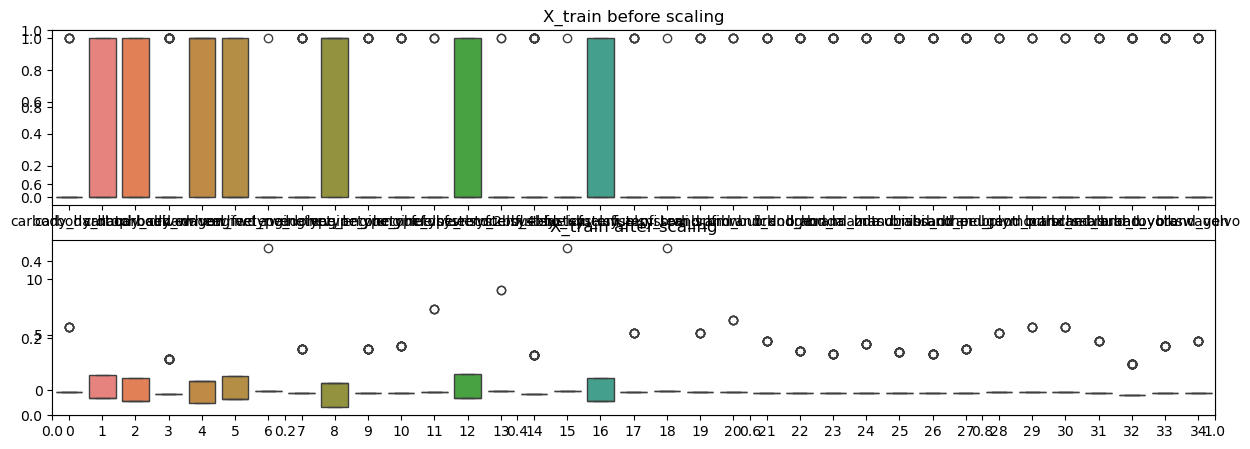

In [380]:
plt.subplots(figsize=(15,5))
plt.subplot(2,1,1)
sns.boxplot(data=X_train_encoded)
plt.title('X_train before scaling')
plt.subplot(2,1,2)
sns.boxplot(data=X_train_final)
plt.title('X_train after scaling')
plt.show()

Linear Regression

R²  : 0.7834704094702812
MAE : 2728.429511389059
RMSE: 4134.454802732985


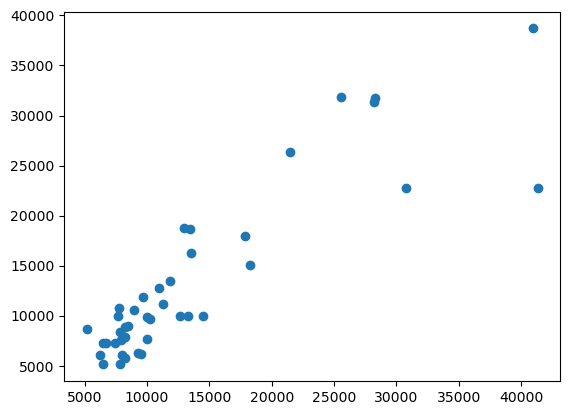

In [381]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

model=LinearRegression()
model.fit(X_train_final,y_train)
y_pred=model.predict(X_test_final)
print("R²  :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
plt.scatter(y_test,y_pred)
plt.show()


Lasso Regression

R²  : 0.7793715457977842
MAE : 2761.2454204043615
RMSE: 4173.403562463894


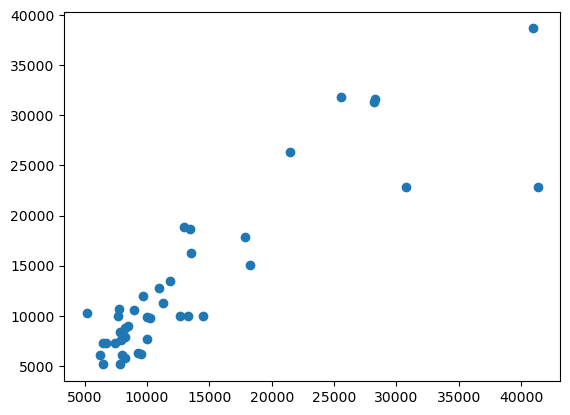

In [382]:
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

lasso=Lasso()
lasso.fit(X_train_final,y_train)
y_pred=lasso.predict(X_test_final)
print("R²  :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
plt.scatter(y_test,y_pred)
plt.show()




Mean Squared error:  17775675.064138204
Root Mean Squared error:  4216.12085502043
Mean Absolute error:  2827.7556416285533
R2 Score:  0.7748319015668652


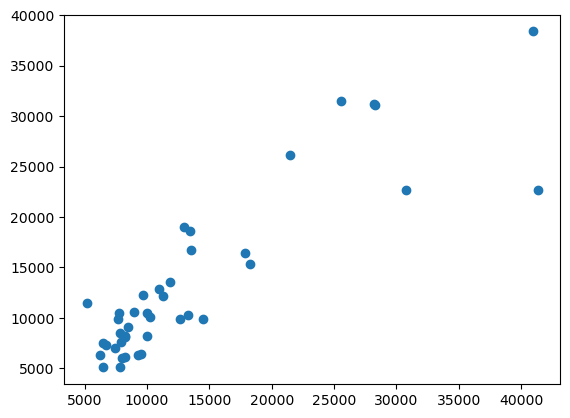

In [ ]:
from sklearn.linear_model import LassoCV
lassocv=LassoCV(cv=4)
lassocv.fit(X_train_final,y_train)
y_pred=lassocv.predict(X_test_final)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,y_pred)
plt.show()

Ridge Regression

R²  : 0.7838904586250294
MAE : 2740.041267914147
RMSE: 4130.442609043119


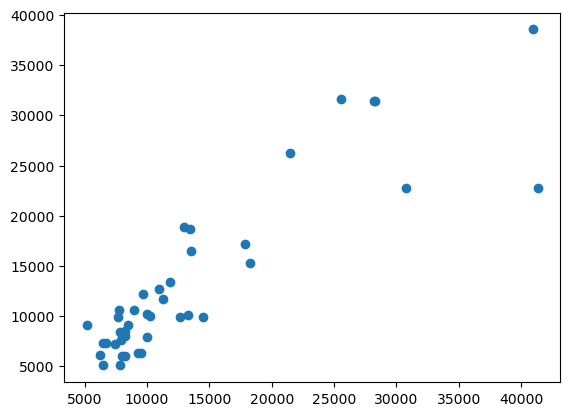

In [384]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

ridge=Ridge()
ridge.fit(X_train_final,y_train)
y_pred=ridge.predict(X_test_final)
print("R²  :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
plt.scatter(y_test,y_pred)
plt.show()


Mean Squared error:  17424863.47503675
Root Mean Squared error:  4174.309939982506
Mean Absolute error:  2839.2278761770085
R2 Score:  0.7792757034557535


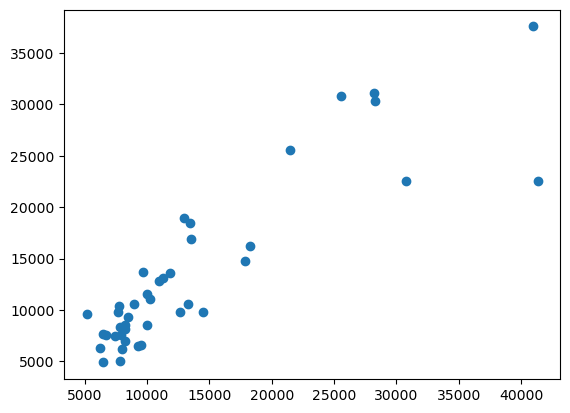

In [390]:
from sklearn.linear_model import RidgeCV
ridgecv=RidgeCV(cv=4)
ridgecv.fit(X_train_final,y_train)
y_pred=ridgecv.predict(X_test_final)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,y_pred)
plt.show()

Elastic Net

R²  : 0.740636666675099
MAE : 2923.7239308421545
RMSE: 4524.951314811972


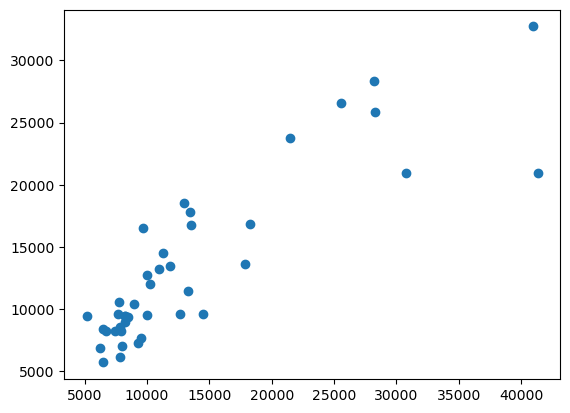

In [386]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

elastic=ElasticNet()
elastic.fit(X_train_final,y_train)
y_pred=elastic.predict(X_test_final)
print("R²  :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
plt.scatter(y_test,y_pred)
plt.show()

Mean Squared error:  45229771.36901166
Root Mean Squared error:  6725.308273158314
Mean Absolute error:  4711.573793319625
R2 Score:  0.4270652689712884


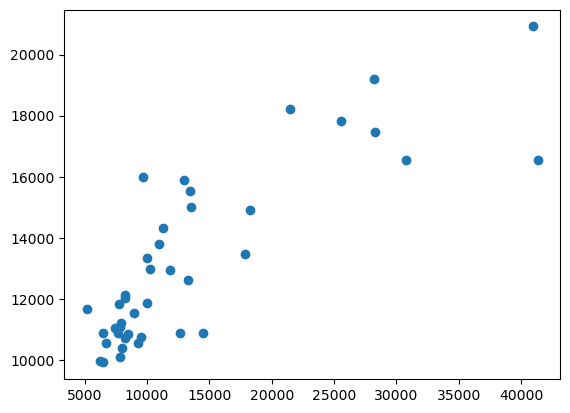

In [387]:
from sklearn.linear_model import ElasticNetCV
elasticcv=ElasticNetCV(cv=5)
elasticcv.fit(X_train_final,y_train)
y_pred=elasticcv.predict(X_test_final)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
mae=mean_absolute_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("Mean Squared error: ",mse)
print("Root Mean Squared error: ",rmse)
print("Mean Absolute error: ",mae)
print("R2 Score: ",score)
plt.scatter(y_test,y_pred)
plt.show()

## Pickling

In [391]:
scaler

StandardScaler()

In [392]:
lasso

Lasso()

In [393]:
import pickle
pickle.dump(scaler,open('scaler.pkl','wb'))
pickle.dump(lasso,open('lasso.pkl','wb'))
